In [26]:
#Step 1 - Load and inspect the Model 2 dataset
import pandas as pd

# Load the Excel file
df = pd.read_excel("Model2_Plain_Corrected_208_Rows.xlsx")

# Display first 5 rows
display(df.head())

# Check rows and columns
print("Dataset shape:", df.shape)



,Match_Number,Date,Team,Opponent,Goals_Scored,Team_xG,Average_Goals_Scored,Average_Age,Transfers_2025,Coach_Salary_EUR,FIFA_Ranking_Apr2026,Forward_Goal_Rate,Squad_Goals,Krupa_xG_Source,Marium_Date,Rosin_Date
0,1,2026-06-11,Mexico,South Africa,2,1.05,1.6,27.90,178,2500000,15,0.206,127,International Friendlies 2025,2026-06-11,2026-06-11
1,1,2026-06-11,South Africa,Mexico,0,1.42,1.5,26.81,49,900000,60,0.202,68,International Friendlies 2025,2026-06-11,2026-06-11
2,2,2026-06-12,Korea Republic,Czechia,2,0.93,1.5,28.07,103,2160000,25,0.336,144,International Friendlies 2025,2026-06-12,2026-06-12
3,2,2026-06-12,Czechia,Korea Republic,1,0.77,2.2,27.62,100,180000,41,0.256,100,International Friendlies 2025,2026-06-12,2026-06-12
4,3,2026-06-12,Canada,Bosnia and Herzegovina,1,1.14,1.1,26.97,90,2500000,30,0.280,141,International Friendlies 2025,2026-06-12,2026-06-12


Dataset shape: (208, 16)


In [27]:
# Step 2 - Check for missing values
print("Dataset shape:", df.shape)
print("Missing values:")
print(df.isnull().sum())

Dataset shape: (208, 16)
Missing values:
Match_Number            0
Date                    0
Team                    0
Opponent                0
Goals_Scored            0
Team_xG                 0
Average_Goals_Scored    0
Average_Age             0
Transfers_2025          0
Coach_Salary_EUR        0
FIFA_Ranking_Apr2026    0
Forward_Goal_Rate       0
Squad_Goals             0
Krupa_xG_Source         0
Marium_Date             0
Rosin_Date              0
dtype: int64


In [11]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

# Check the type of data in each column
print("\nDataset information:")
df.info()


Column names:
['Match_Number', 'Date', 'Team', 'Opponent', 'Goals_Scored', 'Team_xG', 'Average_Goals_Scored', 'Average_Age', 'Transfers_2025', 'Coach_Salary_EUR', 'FIFA_Ranking_Apr2026', 'Forward_Goal_Rate', 'Squad_Goals', 'Krupa_xG_Source', 'Marium_Date', 'Rosin_Date']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Match_Number          208 non-null    int64  
 1   Date                  208 non-null    object 
 2   Team                  208 non-null    object 
 3   Opponent              208 non-null    object 
 4   Goals_Scored          208 non-null    int64  
 5   Team_xG               208 non-null    float64
 6   Average_Goals_Scored  208 non-null    float64
 7   Average_Age           208 non-null    float64
 8   Transfers_2025        208 non-null    int64  
 9   Coach_Salary_EUR      208 non-null  

In [28]:

# Step 3 - Check duplicate records

# Count completely identical rows
print("Duplicate rows:", df.duplicated().sum())

# Count repeated team entries within the same match
print("Duplicate team-match records:",
      df.duplicated(subset=["Match_Number", "Team"]).sum())

# Check the number of different matches
print("Unique matches:", df["Match_Number"].nunique())

# Check how many rows each match has
print("\nRows per match:")
print(df.groupby("Match_Number").size().value_counts())


Duplicate rows: 0
Duplicate team-match records: 0
Unique matches: 104

Rows per match:
2    104
Name: count, dtype: int64


In [13]:

# Step 4.1: Check numerical values

# Display minimum, maximum, and average values
df.describe().round(2)


,Match_Number,Goals_Scored,Team_xG,Average_Goals_Scored,Average_Age,Transfers_2025,Coach_Salary_EUR,FIFA_Ranking_Apr2026,Forward_Goal_Rate,Squad_Goals
count,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00
mean,52.50,1.48,1.41,1.96,27.87,169.89,2035567.31,27.84,0.30,127.88
std,30.09,1.39,0.70,0.67,1.09,144.54,1920522.97,23.05,0.09,48.88
min,1.00,0.00,-0.11,0.70,25.85,0.00,96000.00,1.00,0.12,45.00
25%,26.75,0.00,0.88,1.30,26.97,84.00,605000.00,8.75,0.23,96.00
50%,52.50,1.00,1.32,1.90,27.65,121.00,1600000.00,22.50,0.29,123.50
75%,78.25,2.00,1.92,2.50,28.61,241.00,3000000.00,41.00,0.38,144.00
max,104.00,7.00,2.84,3.70,30.43,660.00,9500000.00,85.00,0.46,266.00


In [14]:

# Step 4.2 - Check for negative values

print("Negative goals scored:",
      (df["Goals_Scored"] < 0).sum())

print("Negative xG values:",
      (df["Team_xG"] < 0).sum())

print("Negative average goals:",
      (df["Average_Goals_Scored"] < 0).sum())

# Display records with negative xG
display(df[df["Team_xG"] < 0])


Negative goals scored: 0
Negative xG values: 3
Negative average goals: 0


,Match_Number,Date,Team,Opponent,Goals_Scored,Team_xG,Average_Goals_Scored,Average_Age,Transfers_2025,Coach_Salary_EUR,FIFA_Ranking_Apr2026,Forward_Goal_Rate,Squad_Goals,Krupa_xG_Source,Marium_Date,Rosin_Date
45,23,2026-06-17,Panama,Ghana,0,-0.11,1.8,30.43,69,725000,33,0.233,127,International Friendlies 2025,2026-06-18,2026-06-18
92,47,2026-06-23,Panama,Croatia,0,-0.11,1.8,30.43,69,725000,33,0.233,127,International Friendlies 2025,2026-06-24,2026-06-24
132,67,2026-06-27,Panama,England,0,-0.11,1.8,30.43,69,725000,33,0.233,127,International Friendlies 2025,2026-06-27,2026-06-27


In [15]:
#Step 4.3 - Mark the invalid xG values
import numpy as np

# Create a separate working copy
df_clean = df.copy()

# Replace negative xG values with missing values
df_clean.loc[df_clean["Team_xG"] < 0, "Team_xG"] = np.nan

# Check the result
print("Invalid xG values:", (df_clean["Team_xG"] < 0).sum())

print("Missing xG values:", df_clean["Team_xG"].isna().sum())


Invalid xG values: 0
Missing xG values: 3


In [16]:

# Step 5.1: Select the target and eight explanatory variables

variables = [
    "Goals_Scored",
    "Team_xG",
    "Average_Goals_Scored",
    "Average_Age",
    "Transfers_2025",
    "Coach_Salary_EUR",
    "FIFA_Ranking_Apr2026",
    "Forward_Goal_Rate",
    "Squad_Goals"
]

# Calculate correlation between variables
correlation = df_clean[variables].corr()

# Display the correlation table
display(correlation.round(2))


,Goals_Scored,Team_xG,Average_Goals_Scored,Average_Age,Transfers_2025,Coach_Salary_EUR,FIFA_Ranking_Apr2026,Forward_Goal_Rate,Squad_Goals
Goals_Scored,1.00,0.27,0.30,-0.10,0.27,0.26,-0.37,0.35,0.29
Team_xG,0.27,1.00,0.65,-0.10,0.49,0.25,-0.65,0.49,0.51
Average_Goals_Scored,0.30,0.65,1.00,-0.09,0.48,0.30,-0.60,0.59,0.52
Average_Age,-0.10,-0.10,-0.09,1.00,0.05,0.07,0.05,-0.09,0.20
Transfers_2025,0.27,0.49,0.48,0.05,1.00,0.78,-0.65,0.44,0.47
Coach_Salary_EUR,0.26,0.25,0.30,0.07,0.78,1.00,-0.55,0.33,0.41
FIFA_Ranking_Apr2026,-0.37,-0.65,-0.60,0.05,-0.65,-0.55,1.00,-0.48,-0.55
Forward_Goal_Rate,0.35,0.49,0.59,-0.09,0.44,0.33,-0.48,1.00,0.67
Squad_Goals,0.29,0.51,0.52,0.20,0.47,0.41,-0.55,0.67,1.00


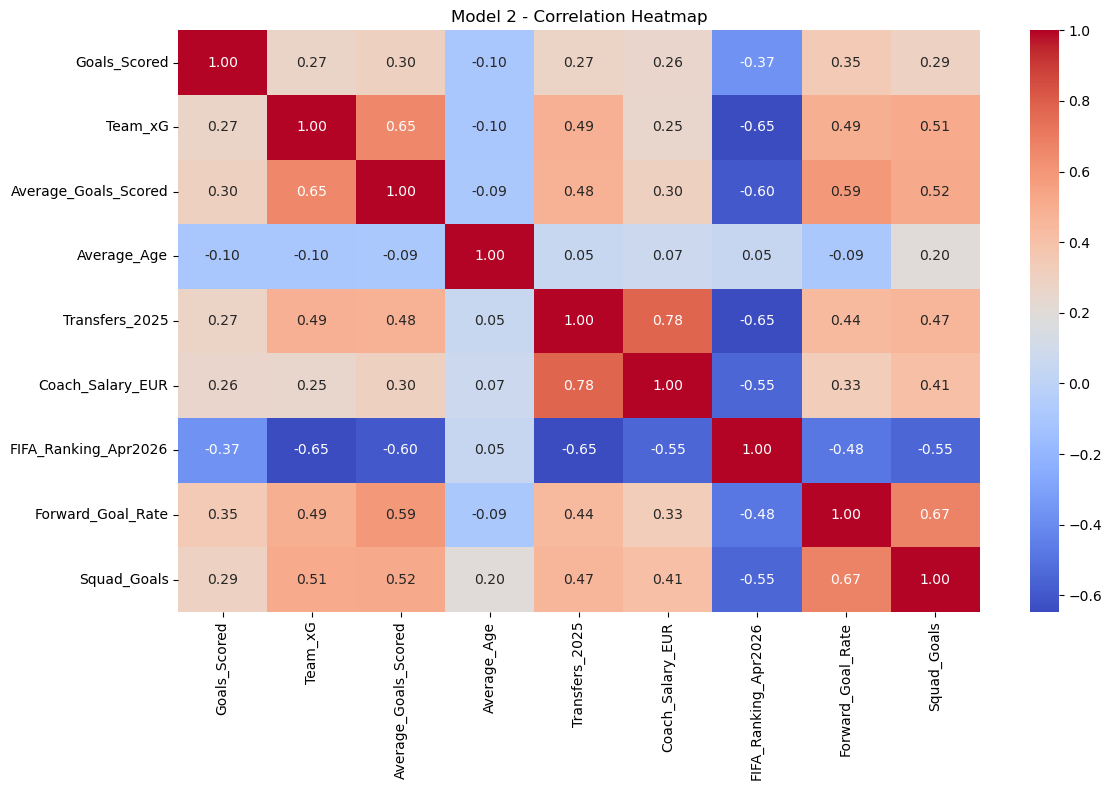

In [18]:

# Step 5.2: Visualise the correlations

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Model 2 - Correlation Heatmap")
plt.tight_layout()
plt.show()


In [19]:
#Step 5.3: Check Multicollinearity (VIF)
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select our eight explanatory variables
X_columns = [
    "Team_xG",
    "Average_Goals_Scored",
    "Average_Age",
    "Transfers_2025",
    "Coach_Salary_EUR",
    "FIFA_Ranking_Apr2026",
    "Forward_Goal_Rate",
    "Squad_Goals"
]

# Use rows with complete values for this check
X_vif = df_clean[X_columns].dropna().copy()

# Add a constant for the VIF calculation
from statsmodels.tools.tools import add_constant
X_vif = add_constant(X_vif)

# Calculate VIF for each explanatory variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Display results (excluding the constant)
display(vif_data[vif_data["Variable"] != "const"].round(2))


,Variable,VIF
1,Team_xG,2.43
2,Average_Goals_Scored,2.23
3,Average_Age,1.21
4,Transfers_2025,3.55
5,Coach_Salary_EUR,2.99
6,FIFA_Ranking_Apr2026,2.64
7,Forward_Goal_Rate,2.29
8,Squad_Goals,2.55


In [20]:

# Step 6.1: Separate explanatory and target variables

X_columns = [
    "Team_xG",
    "Average_Goals_Scored",
    "Average_Age",
    "Transfers_2025",
    "Coach_Salary_EUR",
    "FIFA_Ranking_Apr2026",
    "Forward_Goal_Rate",
    "Squad_Goals"
]

# Select the eight explanatory variables
X = df_clean[X_columns]

# Select the target variable
y = df_clean["Goals_Scored"]

# Check dataset dimensions
print("X shape:", X.shape)
print("y shape:", y.shape)

# Check missing values
print("Missing X values:", X.isna().sum().sum())


X shape: (208, 8)
y shape: (208,)
Missing X values: 3


In [21]:
#Step 6.2 — Split the dataset into training and testing sets
'''Training set (80%): Used to teach the model relationships between the variables and goals scored.



Testing set (20%): Used to check how well the model predicts goals for matches it hasn't seen.'''

"Training set (80%): Used to teach the model relationships between the variables and goals scored.\n\n\n\nTesting set (20%): Used to check how well the model predicts goals for matches it hasn't seen."

In [23]:

# Step 6.2: Split data by match number

from sklearn.model_selection import GroupShuffleSplit

# Create an 80% training and 20% testing split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Keep both teams from the same match together
train_idx, test_idx = next(
    splitter.split(X, y, groups=df_clean["Match_Number"])
)

# Separate the training and testing records
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Display the results
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Confirm no match appears in both sets
train_matches = set(df_clean.iloc[train_idx]["Match_Number"])
test_matches = set(df_clean.iloc[test_idx]["Match_Number"])

print("Matches shared between sets:",
      len(train_matches.intersection(test_matches)))


Training rows: 166
Testing rows: 42
Matches shared between sets: 0


In [17]:
#Step 6.3: Handle missing xG values

In [24]:

from sklearn.impute import SimpleImputer
import pandas as pd

# Create an imputer using the training data
imputer = SimpleImputer(strategy="median")

# Learn the median from training data and fill missing values
X_train_ready = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_columns,
    index=X_train.index
)

# Use the same training median for the testing data
X_test_ready = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_columns,
    index=X_test.index
)

# Check the results
print("Missing training values:",
      X_train_ready.isna().sum().sum())

print("Missing testing values:",
      X_test_ready.isna().sum().sum())

print("Training shape:", X_train_ready.shape)
print("Testing shape:", X_test_ready.shape)


Missing training values: 0
Missing testing values: 0
Training shape: (166, 8)
Testing shape: (42, 8)


In [25]:

# Step 7.1: Train the Multiple Linear Regression Model

from sklearn.linear_model import LinearRegression

# Create the linear regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train_ready, y_train)

# Display the model's intercept and coefficients
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Variable": X_columns,
    "Coefficient": model.coef_
})

display(coefficients.round(4))


Intercept: 3.7164679758703265


,Variable,Coefficient
0,Team_xG,-0.1946
1,Average_Goals_Scored,0.0687
2,Average_Age,-0.0901
3,Transfers_2025,0.0001
4,Coach_Salary_EUR,0.0000
5,FIFA_Ranking_Apr2026,-0.0163
6,Forward_Goal_Rate,3.4141
7,Squad_Goals,-0.0016


In [20]:

# Step 7.2: Predict goals scored

# Predict goals for the testing dataset
y_pred = model.predict(X_test_ready)

# Compare actual goals with predicted goals
predictions = pd.DataFrame({
    "Actual_Goals": y_test.values,
    "Predicted_Goals": y_pred
})

# Display the first 10 predictions
display(predictions.head(10).round(2))


,Actual_Goals,Predicted_Goals
0,2,1.49
1,0,0.77
2,1,0.72
3,1,1.40
4,1,1.46
5,0,1.64
6,0,1.86
7,0,0.56
8,3,2.17
9,0,1.76


In [21]:

# Step 8.1: Evaluate the regression model

import numpy as np
from sklearn import metrics

# Calculate evaluation metrics
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, y_pred)

# Calculate Normalised RMSE
goal_range = y_test.max() - y_test.min()

if goal_range > 0:
    nrmse = rmse / goal_range
else:
    nrmse = np.nan

# Display results
print("MODEL 2 PERFORMANCE")
print("-------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("Normalised RMSE:", round(nrmse, 4))
print("R-squared (R²):", round(r2, 4))


MODEL 2 PERFORMANCE
-------------------
MAE: 1.0321
MSE: 1.7807
RMSE: 1.3344
Normalised RMSE: 0.2224
R-squared (R²): 0.1779


In [22]:

# Step 8.2: Compare regression against a baseline

# Calculate average goals from training data
baseline_mean = y_train.mean()

# Predict the same average for every test record
baseline_pred = np.full(len(y_test), baseline_mean)

# Calculate baseline performance
baseline_mae = metrics.mean_absolute_error(y_test, baseline_pred)
baseline_mse = metrics.mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = metrics.r2_score(y_test, baseline_pred)

# Compare the two models
comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R-squared"],
    "Linear Regression": [mae, mse, rmse, r2],
    "Baseline": [
        baseline_mae,
        baseline_mse,
        baseline_rmse,
        baseline_r2
    ]
})

display(comparison.round(4))


,Metric,Linear Regression,Baseline
0,MAE,1.0321,1.2461
1,MSE,1.7807,2.2121
2,RMSE,1.3344,1.4873
3,R-squared,0.1779,-0.0213


In [23]:

# Step 9.1: Five-fold cross-validation

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
import pandas as pd

# Create a pipeline for missing values and regression
cv_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

# Divide the matches into 5 groups
cv = GroupKFold(n_splits=5)

# Evaluate the model five times
cv_results = cross_validate(
    cv_model,
    X,
    y,
    groups=df_clean["Match_Number"],
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    }
)

# Display results
cv_table = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": -cv_results["test_MAE"],
    "R2": cv_results["test_R2"]
})

display(cv_table.round(4))

print("Average MAE:", round(cv_table["MAE"].mean(), 4))
print("Average R2:", round(cv_table["R2"].mean(), 4))


,Fold,MAE,R2
0,1,1.0808,-0.0205
1,2,1.2173,0.1509
2,3,0.8968,0.0428
3,4,0.9582,0.0408
4,5,0.9239,0.2166


Average MAE: 1.0154
Average R2: 0.0861


In [24]:
#Step 10.1 - Compare original and standardised regression

# Step 10.1: Test standardisation

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import numpy as np
import pandas as pd

# Create a model with standardisation
scaled_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearRegression()
)

# Train using the original training records
scaled_model.fit(X_train, y_train)

# Predict goals for the test records
scaled_pred = scaled_model.predict(X_test)

# Evaluate the standardised model
scaled_mae = metrics.mean_absolute_error(y_test, scaled_pred)
scaled_rmse = np.sqrt(metrics.mean_squared_error(y_test, scaled_pred))
scaled_r2 = metrics.r2_score(y_test, scaled_pred)

# Compare both models
scaling_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Original Regression": [mae, rmse, r2],
    "Standardised Regression": [
        scaled_mae, scaled_rmse, scaled_r2
    ]
})

display(scaling_comparison.round(4))


,Metric,Original Regression,Standardised Regression
0,MAE,1.0321,1.0321
1,RMSE,1.3344,1.3344
2,R2,0.1779,0.1779


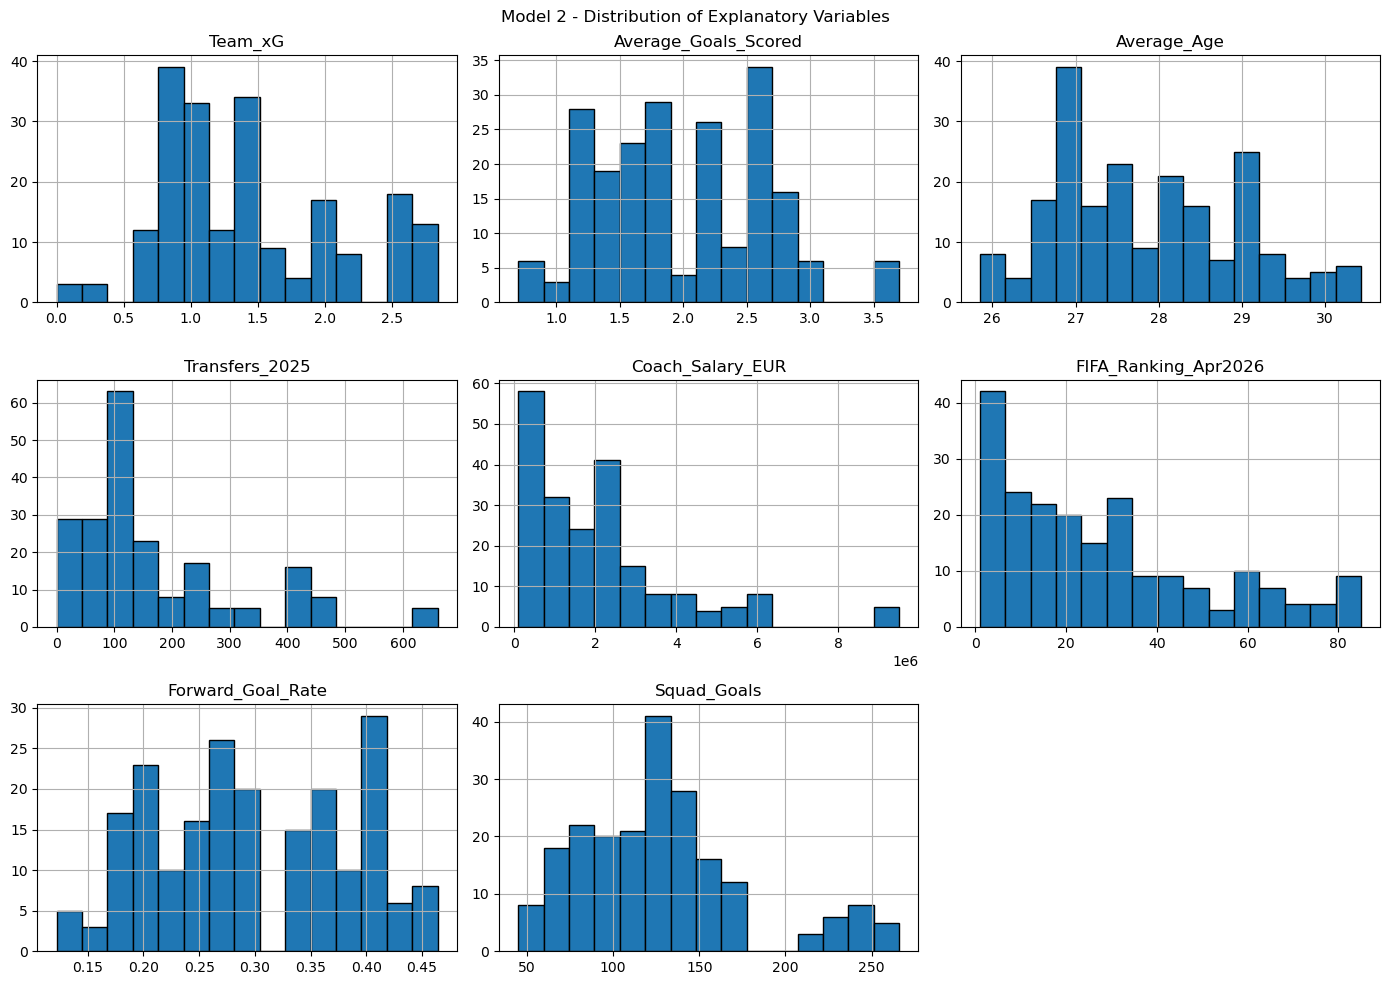

In [25]:
#Step 10.2 - Check the distribution of our explanatory variables


# Step 10.2: Check variable distributions

import matplotlib.pyplot as plt

# Create histograms for all eight explanatory variables
X.hist(
    figsize=(14, 10),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Model 2 - Distribution of Explanatory Variables")
plt.tight_layout()
plt.show()


In [26]:

# Step 10.3: Test logarithmic transformation

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Make separate copies of training and testing data
X_train_log = X_train.copy()
X_test_log = X_test.copy()

# Apply log transformation to two variables
log_columns = ["Transfers_2025", "Coach_Salary_EUR"]

for column in log_columns:
    X_train_log[column] = np.log1p(X_train_log[column])
    X_test_log[column] = np.log1p(X_test_log[column])

# Fill missing values using training data only
log_imputer = SimpleImputer(strategy="median")

X_train_log_ready = log_imputer.fit_transform(X_train_log)
X_test_log_ready = log_imputer.transform(X_test_log)

# Build the regression model
log_model = LinearRegression()
log_model.fit(X_train_log_ready, y_train)

# Predict goals
log_pred = log_model.predict(X_test_log_ready)

# Evaluate the transformed model
log_mae = metrics.mean_absolute_error(y_test, log_pred)
log_rmse = np.sqrt(metrics.mean_squared_error(y_test, log_pred))
log_r2 = metrics.r2_score(y_test, log_pred)

# Compare results
log_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Original Model": [mae, rmse, r2],
    "Log-Transformed Model": [log_mae, log_rmse, log_r2]
})

display(log_comparison.round(4))


,Metric,Original Model,Log-Transformed Model
0,MAE,1.0321,1.0424
1,RMSE,1.3344,1.3360
2,R2,0.1779,0.1759


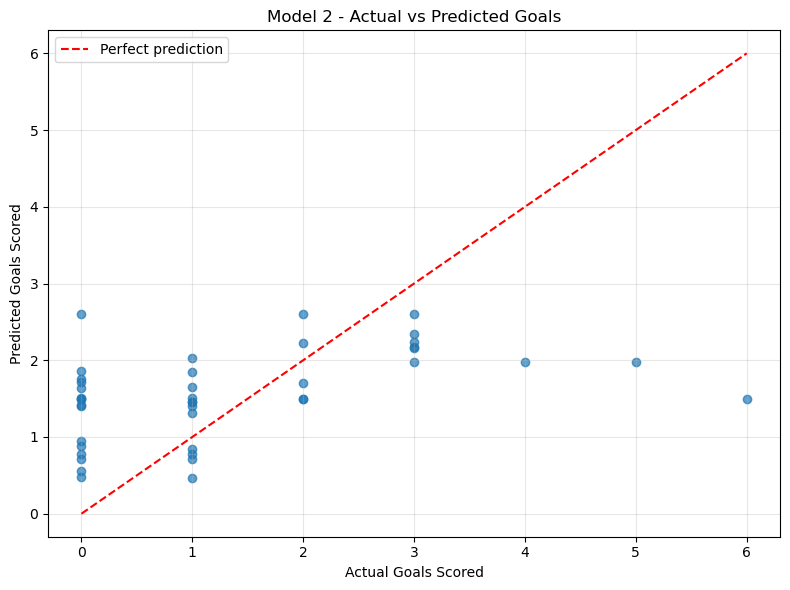

In [27]:

# Step 10.4: Actual vs Predicted Goals

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

# Plot actual and predicted goals
plt.scatter(y_test, y_pred, alpha=0.7)

# Draw the perfect prediction line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

plt.xlabel("Actual Goals Scored")
plt.ylabel("Predicted Goals Scored")
plt.title("Model 2 - Actual vs Predicted Goals")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


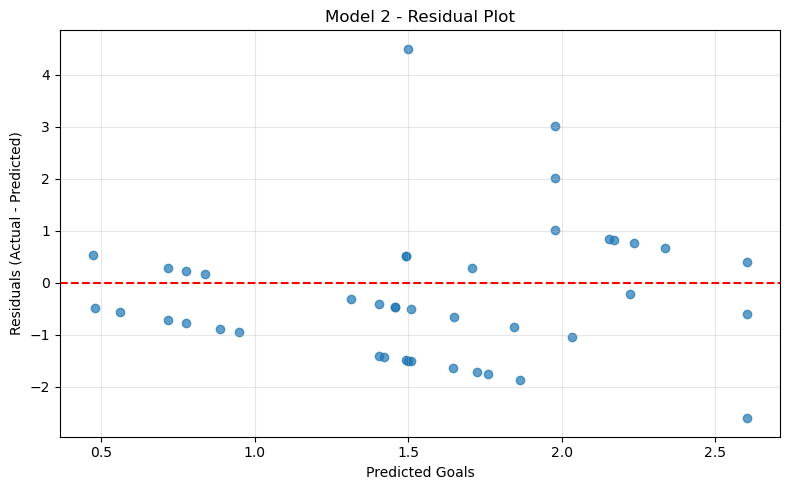

In [28]:

# Step 10.5: Residual Analysis

import matplotlib.pyplot as plt

# Calculate prediction errors
residuals = y_test.values - y_pred

# Create residual scatterplot
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)

# Draw a horizontal reference line at zero
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Goals")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Model 2 - Residual Plot")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:
'''
Step 11: Conclusion

The objective of Model 2 was to predict the number of goals scored by a team in a World Cup match using eight explanatory variables. The model performed 
better than the baseline, with an R² of 0.18 and an average prediction error of about 1 goal. However, the results show that accurately predicting goals 
scored remains difficult.

'''

'\nStep 11: Conclusion\n\nThe objective of Model 2 was to predict the number of goals scored by a team in a World Cup match using eight explanatory variables. The model performed \nbetter than the baseline, with an R² of 0.18 and an average prediction error of about 1 goal. However, the results show that accurately predicting goals \nscored remains difficult.\n\n'